# 10 — Calibración de la logística con recuentos

Objetivos:
- Mantener fija la candidata elegida: regresión logística con los tres recuentos.
- Comparar probabilidades sin calibrar y con calibración sigmoide.
- Evaluar calidad probabilística, discriminación y decisiones de alerta.
- Conservar la evaluación temporal de 2022 y 2023 y la separación por estudiante.

Una probabilidad bien calibrada busca que, entre casos con riesgo cercano a 0,70, aproximadamente el 70 % resulte positivo. Esto no significa que se pueda asegurar el resultado de una persona.

| Año evaluado | Último año de entrenamiento y calibración | Seguimiento para evaluar |
|---|---:|---|
| 2022 | 2020 | 2023 y 2024 |
| 2023 | 2021 | 2024 y 2025 |

Se utilizan cinco folds externos por estudiante y tres folds internos para calibrar. El preprocesamiento se aprende dentro de cada ajuste. Ejecutar todas las celdas en orden desde un kernel nuevo.

**Alcance:** no se buscan nuevos modelos ni hiperparámetros. El corte 0,50 se conserva como referencia; los 150 contactos siguen siendo un ejemplo. Calibrar no garantiza aumentar el recall ni mejorar ROC-AUC. Los años ya fueron inspeccionados, por lo que el análisis sigue siendo exploratorio. No se publica ni se guarda todavía un modelo final.

Referencia: [calibración de probabilidades en scikit-learn](https://scikit-learn.org/stable/modules/calibration.html).


## 1. Entorno, imports y parámetros

Este cuaderno utiliza la misma logística del notebook 09. Se lee la configuración sin modificarla. El método sigmoide se fija de antemano para evitar abrir otra búsqueda de calibradores.


In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import sklearn

from IPython.display import display
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    brier_score_loss,
    log_loss,
)

PROJ_ROOT = Path.cwd()

if PROJ_ROOT.name == "notebooks":
    PROJ_ROOT = PROJ_ROOT.parent

assert (PROJ_ROOT / "src").is_dir(), (
    f"No se encontró la raíz del proyecto desde {PROJ_ROOT}"
)

os.chdir(PROJ_ROOT)

if str(PROJ_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJ_ROOT))

from src.data.load_data import load_processed, load_raw
from src.features.build_features import FEATURES_COLS

with open("configs/config.yaml", encoding="utf-8") as archivo:
    config = yaml.safe_load(archivo)

VENTANA = int(config["target"]["ventana_anios"])
ANIOS_EVALUACION = [2022, 2023]
N_FOLDS_INTERNOS = 3
METODO_CALIBRACION = "sigmoid"

UMBRAL_REFERENCIA = 0.50
CORTES_REVISION = [0.50, 0.40, 0.30, 0.20]
CAPACIDAD_EJEMPLO = 150
N_GRUPOS_CALIBRACION = 5

CLAVES = ["id_alumno", "anio_academico"]
RECUENTOS = [
    "asignaturas_cursadas",
    "inscripciones_finales",
    "finales_aprobados",
]
COLUMNAS_MODELO = list(FEATURES_COLS) + RECUENTOS
CARPETA_REPORTES = PROJ_ROOT / "reports"

assert max(ANIOS_EVALUACION) + VENTANA <= int(
    config["target"]["censurar_hasta"]
)

print("Proyecto:", PROJ_ROOT)
print("Candidata: logística con recuentos")
print("Predictores:", len(COLUMNAS_MODELO))
print("scikit-learn:", sklearn.__version__)


Proyecto: /Users/alejo/Desktop/alerta-temprana-desercion
Candidata: logística con recuentos
Predictores: 16
scikit-learn: 1.9.1


## 2. Datos preparados y folds externos

Se recuperan el target y los folds anteriores. No se reconstruyen las etiquetas ni se recalculan las features.


In [2]:
df = (
    load_processed()
    .sort_values(CLAVES)
    .reset_index(drop=True)
)

referencia = pd.read_csv(
    PROJ_ROOT / "reports" / "predicciones_baseline_oof.csv"
)

assert not df.duplicated(CLAVES).any()
assert not referencia.duplicated(CLAVES).any()
assert len(df) == len(referencia)

referencia = referencia[
    CLAVES + ["fold", "abandono_real"]
].rename(columns={"abandono_real": "target_referencia"})

df = df.merge(
    referencia,
    on=CLAVES,
    how="left",
    sort=False,
    validate="one_to_one",
)

assert df[["fold", "target_referencia"]].notna().all().all()
assert df["abandono"].isin([0, 1]).all()
assert df["abandono"].astype(int).eq(df["target_referencia"]).all()

df["fold"] = df["fold"].astype(int)

assert df.groupby("id_alumno")["fold"].nunique().eq(1).all()
assert df["fold"].nunique() == int(config["split"]["n_splits"])

print("Registros:", len(df))
print("Estudiantes:", df["id_alumno"].nunique())


Registros: 1979
Estudiantes: 1019


## 3. Edad y matriz de entrada

Se recuperan únicamente las posiciones de las edades originalmente iguales a cero. La imputación se aprenderá dentro de cada ajuste, incluidos los de la calibración interna. Se conservan los dieciséis predictores de la candidata.


In [3]:
edades_originales = load_raw()[
    CLAVES + ["edad"]
].rename(columns={"edad": "edad_original"})

df = df.merge(
    edades_originales,
    on=CLAVES,
    how="left",
    sort=False,
    validate="one_to_one",
).reset_index(drop=True)

assert df["edad_original"].notna().all()

df["edad"] = df["edad"].astype(float)
df.loc[df["edad_original"].eq(0), "edad"] = np.nan

assert len(COLUMNAS_MODELO) == len(set(COLUMNAS_MODELO))
assert set(COLUMNAS_MODELO).issubset(df.columns)
assert not {
    "id_alumno", "anio_academico", "abandono",
    "prox_actividad", "target_referencia",
}.intersection(COLUMNAS_MODELO)

X = df[COLUMNAS_MODELO].copy()
y = df["abandono"].astype(int)
groups = df["id_alumno"]

assert all(pd.api.types.is_numeric_dtype(X[col]) for col in X)
assert not np.isinf(X.to_numpy(dtype=float)).any()

print("X:", X.shape)
print("Edades pendientes de imputación:", X["edad"].isna().sum())


X: (1979, 16)
Edades pendientes de imputación: 3


## 4. Separación temporal externa

El año y el fold evaluados quedan fuera del ajuste del modelo y del calibrador. Todas las etiquetas usadas para entrenar o calibrar deben estar disponibles al cierre del año simulado.


In [4]:
particiones_externas = []
filas = []

for anio in ANIOS_EVALUACION:
    limite = anio - VENTANA

    for fold in sorted(df["fold"].unique()):
        idx_train = np.flatnonzero(
            (
                df["anio_academico"].le(limite)
                & df["fold"].ne(fold)
            ).to_numpy()
        )
        idx_valid = np.flatnonzero(
            (
                df["anio_academico"].eq(anio)
                & df["fold"].eq(fold)
            ).to_numpy()
        )

        assert len(idx_train) > 0 and len(idx_valid) > 0
        assert y.iloc[idx_train].nunique() == 2
        assert y.iloc[idx_valid].nunique() == 2
        assert set(groups.iloc[idx_train]).isdisjoint(
            set(groups.iloc[idx_valid])
        )
        assert (
            df.iloc[idx_train]["anio_academico"] + VENTANA
        ).le(anio).all()

        particiones_externas.append({
            "anio": anio,
            "fold": int(fold),
            "idx_train": idx_train,
            "idx_valid": idx_valid,
        })

        filas.append({
            "anio_evaluacion": anio,
            "fold_externo": int(fold),
            "ultimo_anio_train": limite,
            "registros_train": len(idx_train),
            "registros_valid": len(idx_valid),
            "positivos_valid": int(y.iloc[idx_valid].sum()),
        })

assert len(particiones_externas) == (
    len(ANIOS_EVALUACION) * int(config["split"]["n_splits"])
)

display(pd.DataFrame(filas))


,anio_evaluacion,fold_externo,ultimo_anio_train,registros_train,registros_valid,positivos_valid
0,2022,1,2020,539,82,19
1,2022,2,2020,552,85,21
2,2022,3,2020,542,83,26
3,2022,4,2020,542,85,25
4,2022,5,2020,545,86,25
5,2023,1,2021,776,121,31
6,2023,2,2021,778,120,24
7,2023,3,2021,771,115,31
8,2023,4,2021,775,117,40
9,2023,5,2021,776,116,26


## 5. Pipeline de la candidata

Se mantienen imputación, estandarización y regresión logística sin cambiar hiperparámetros. Así se estudia únicamente el efecto de calibrar.


In [5]:
pipeline_logistica = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("modelo", LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=2000,
        class_weight=None,
    )),
])

pipeline_logistica


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacion', ...), ('escalado', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto 

## 6. Particiones internas para calibrar

Los tres folds internos separan estudiantes dentro del entrenamiento externo. Generan predicciones fuera de muestra para ajustar la sigmoide; no incluyen el año ni los estudiantes de evaluación externa. Dentro de ese historial disponible, la separación interna es por estudiante y no constituye otro backtest temporal.


In [6]:
def construir_cv_interno(X_train, y_train, grupos_train):
    cv = GroupKFold(n_splits=N_FOLDS_INTERNOS)
    divisiones = list(cv.split(X_train, y_train, grupos_train))
    veces_validado = np.zeros(len(X_train), dtype=int)

    for idx_ajuste, idx_calibracion in divisiones:
        assert set(grupos_train.iloc[idx_ajuste]).isdisjoint(
            set(grupos_train.iloc[idx_calibracion])
        )
        assert y_train.iloc[idx_ajuste].nunique() == 2
        assert y_train.iloc[idx_calibracion].nunique() == 2
        veces_validado[idx_calibracion] += 1

    assert (veces_validado == 1).all()
    return divisiones


## 7. Comparación sin calibrar y con sigmoide

CalibratedClassifierCV recibe divisiones internas explícitas. Con ensemble=False obtiene las probabilidades internas fuera de muestra para calibrar y después reajusta el estimador con todo el entrenamiento externo. La referencia sin calibrar utiliza ese mismo conjunto. En total se realizan 50 ajustes de logística: diez referencias y cuarenta ajustes internos/finales de calibración.


In [7]:
bloques_predicciones = []
auditoria_interna = []

for particion in particiones_externas:
    anio = particion["anio"]
    fold = particion["fold"]
    idx_train = particion["idx_train"]
    idx_valid = particion["idx_valid"]

    X_train = X.iloc[idx_train].reset_index(drop=True)
    y_train = y.iloc[idx_train].reset_index(drop=True)
    grupos_train = groups.iloc[idx_train].reset_index(drop=True)

    divisiones_internas = construir_cv_interno(
        X_train, y_train, grupos_train
    )

    for numero, (idx_ajuste, idx_calibracion) in enumerate(
        divisiones_internas, start=1
    ):
        auditoria_interna.append({
            "anio_evaluacion": anio,
            "fold_externo": fold,
            "fold_interno": numero,
            "registros_ajuste": len(idx_ajuste),
            "registros_calibracion": len(idx_calibracion),
            "estudiantes_ajuste": grupos_train.iloc[idx_ajuste].nunique(),
            "estudiantes_calibracion": grupos_train.iloc[
                idx_calibracion
            ].nunique(),
            "ultima_etiqueta_disponible": int(
                df.iloc[idx_train]["anio_academico"].max() + VENTANA
            ),
        })

    sin_calibrar = clone(pipeline_logistica)
    sin_calibrar.fit(X_train, y_train)

    calibrado = CalibratedClassifierCV(
        estimator=clone(pipeline_logistica),
        method=METODO_CALIBRACION,
        cv=divisiones_internas,
        ensemble=False,
        n_jobs=1,
    )
    calibrado.fit(X_train, y_train)

    for variante, estimador in [
        ("sin_calibrar", sin_calibrar),
        ("sigmoide", calibrado),
    ]:
        prob = estimador.predict_proba(X.iloc[idx_valid])[:, 1]
        assert np.isfinite(prob).all()
        assert ((prob >= 0) & (prob <= 1)).all()

        salida = df.iloc[idx_valid][CLAVES + ["fold"]].copy()
        salida["modelo"] = "logistica_recuentos"
        salida["variante"] = variante
        salida["abandono_real"] = y.iloc[idx_valid].to_numpy()
        salida["probabilidad_abandono"] = prob
        salida["ultimo_anio_train"] = anio - VENTANA

        bloques_predicciones.append(salida)

    print(f"Evaluación {anio} — fold externo {fold} terminado")

predicciones_calibracion = pd.concat(
    bloques_predicciones, ignore_index=True
)
auditoria_interna = pd.DataFrame(auditoria_interna)

assert not predicciones_calibracion.duplicated(
    ["variante"] + CLAVES
).any()
assert predicciones_calibracion.groupby(CLAVES)["variante"].nunique().eq(2).all()
assert predicciones_calibracion.groupby(CLAVES)["abandono_real"].nunique().eq(1).all()
assert auditoria_interna["ultima_etiqueta_disponible"].le(
    auditoria_interna["anio_evaluacion"]
).all()

display(
    predicciones_calibracion.groupby(
        ["anio_academico", "variante"]
    ).size().rename("predicciones")
)
display(auditoria_interna.head(6))


Evaluación 2022 — fold externo 1 terminado
Evaluación 2022 — fold externo 2 terminado
Evaluación 2022 — fold externo 3 terminado
Evaluación 2022 — fold externo 4 terminado
Evaluación 2022 — fold externo 5 terminado
Evaluación 2023 — fold externo 1 terminado
Evaluación 2023 — fold externo 2 terminado
Evaluación 2023 — fold externo 3 terminado
Evaluación 2023 — fold externo 4 terminado
Evaluación 2023 — fold externo 5 terminado


anio_academico  variante    
2022            sigmoide        421
                sin_calibrar    421
2023            sigmoide        589
                sin_calibrar    589
Name: predicciones, dtype: int64

,anio_evaluacion,fold_externo,fold_interno,registros_ajuste,registros_calibracion,estudiantes_ajuste,estudiantes_calibracion,ultima_etiqueta_disponible
0,2022,1,1,359,180,156,78,2022
1,2022,1,2,359,180,156,78,2022
2,2022,1,3,360,179,156,78,2022
3,2022,2,1,368,184,159,79,2022
4,2022,2,2,368,184,159,79,2022
5,2022,2,3,368,184,158,80,2022


## 8. Calidad probabilística y clasificación

Brier y log loss deben disminuir para indicar mejor calidad probabilística en esta evaluación. También dependen de la discriminación y no prueban por sí solos una buena calibración: se revisan junto con la curva de fiabilidad. ROC-AUC y Average Precision evalúan ordenación; precisión y recall usan el corte de referencia.


In [8]:
def resumir_alertas(grupo, alertas):
    real = grupo["abandono_real"].to_numpy(dtype=int)
    alertas = np.asarray(alertas, dtype=bool)
    assert alertas.ndim == 1 and len(alertas) == len(real)

    positivos = real == 1
    tp = int((positivos & alertas).sum())
    fp = int((~positivos & alertas).sum())
    fn = int((positivos & ~alertas).sum())

    return {
        "registros": len(grupo),
        "positivos": int(positivos.sum()),
        "alertas": int(alertas.sum()),
        "verdaderos_positivos": tp,
        "falsos_positivos": fp,
        "falsos_negativos": fn,
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / (tp + fn) if tp + fn else np.nan,
    }


def evaluar_probabilidades(grupo):
    real = grupo["abandono_real"].astype(int)
    prob = grupo["probabilidad_abandono"]

    return {
        **resumir_alertas(grupo, prob.ge(UMBRAL_REFERENCIA)),
        "brier": brier_score_loss(real, prob),
        "log_loss": log_loss(real, prob, labels=[0, 1]),
        "roc_auc": roc_auc_score(real, prob),
        "average_precision": average_precision_score(real, prob),
        "probabilidad_media": prob.mean(),
        "proporcion_positivos": real.mean(),
    }


filas_folds = []
for (anio, variante, fold), grupo in predicciones_calibracion.groupby(
    ["anio_academico", "variante", "fold"]
):
    filas_folds.append({
        "anio_evaluacion": int(anio),
        "variante": variante,
        "fold": int(fold),
        **evaluar_probabilidades(grupo),
    })

metricas_folds = pd.DataFrame(filas_folds)

filas_anuales = []
for (anio, variante), grupo in predicciones_calibracion.groupby(
    ["anio_academico", "variante"]
):
    filas_anuales.append({
        "anio_evaluacion": int(anio),
        "variante": variante,
        **evaluar_probabilidades(grupo),
    })

metricas_anuales = pd.DataFrame(filas_anuales)

display(
    metricas_anuales[[
        "anio_evaluacion", "variante", "brier", "log_loss",
        "roc_auc", "average_precision", "precision", "recall",
        "alertas", "falsos_negativos",
    ]].round(4)
)

display(
    metricas_folds.groupby(["anio_evaluacion", "variante"])[
        ["brier", "log_loss", "roc_auc", "average_precision"]
    ].agg(["mean", "std"]).round(4)
)


,anio_evaluacion,variante,brier,log_loss,roc_auc,average_precision,precision,recall,alertas,falsos_negativos
0,2022,sigmoide,0.1379,0.4364,0.8410,0.7208,0.8356,0.5259,73,55
1,2022,sin_calibrar,0.1295,0.4184,0.8410,0.7246,0.7889,0.6121,90,45
2,2023,sigmoide,0.1482,0.4661,0.7756,0.6295,0.7564,0.3882,78,93
3,2023,sin_calibrar,0.1487,0.4750,0.7782,0.6381,0.7045,0.4079,88,90


brier         log_loss         roc_auc          \
                                mean     std     mean     std    mean     std   
anio_evaluacion variante                                                        
2022            sigmoide      0.1381  0.0168   0.4370  0.0428  0.8423  0.0334   
                sin_calibrar  0.1297  0.0155   0.4189  0.0397  0.8423  0.0334   
2023            sigmoide      0.1482  0.0173   0.4662  0.0339  0.7708  0.0363   
                sin_calibrar  0.1488  0.0181   0.4752  0.0329  0.7708  0.0363   

                             average_precision          
                                          mean     std  
anio_evaluacion variante                                
2022            sigmoide                0.7387  0.0700  
                sin_calibrar            0.7387  0.0700  
2023            sigmoide                0.6348  0.0869  
                sin_calibrar            0.6348  0.0869

## 9. Diferencias por fold

Se compara cada variante calibrada con su referencia en los mismos casos. En Brier y log loss, una diferencia negativa favorece la calibración. No se interpreta la desviación entre folds como intervalo de confianza.


In [9]:
columnas_metricas = ["brier", "log_loss", "roc_auc", "average_precision"]

antes = (
    metricas_folds.loc[metricas_folds["variante"].eq("sin_calibrar")]
    .set_index(["anio_evaluacion", "fold"])[columnas_metricas]
    .sort_index()
)
despues = (
    metricas_folds.loc[metricas_folds["variante"].eq("sigmoide")]
    .set_index(["anio_evaluacion", "fold"])[columnas_metricas]
    .sort_index()
)

assert antes.index.equals(despues.index)

diferencias_folds = despues - antes
diferencias_folds.columns = [
    f"delta_{columna}" for columna in diferencias_folds.columns
]
diferencias_folds = diferencias_folds.reset_index()

display(
    diferencias_folds.groupby("anio_evaluacion")[[
        "delta_brier", "delta_log_loss",
        "delta_roc_auc", "delta_average_precision",
    ]].agg(["mean", "min", "max"]).round(5)
)


delta_brier                   delta_log_loss           \
                       mean      min      max           mean      min   
anio_evaluacion                                                         
2022                0.00846  0.00450  0.01521        0.01807  0.00772   
2023               -0.00055 -0.00257  0.00105       -0.00894 -0.01493   

                         delta_roc_auc           delta_average_precision       \
                     max          mean  min  max                    mean  min   
anio_evaluacion                                                                 
2022             0.03625           0.0  0.0  0.0                     0.0  0.0   
2023             0.00132           0.0  0.0  0.0                     0.0  0.0   

                      
                 max  
anio_evaluacion       
2022             0.0  
2023             0.0

## 10. Grupos de fiabilidad

Se forman cinco grupos por cuantiles de las probabilidades de cada año y variante. Se compara su riesgo medio con la frecuencia observada, mostrando el número de casos. Estos grupos describen la calibración: no son las bandas operativas de riesgo.


In [10]:
filas = []

for (anio, variante), grupo in predicciones_calibracion.groupby(
    ["anio_academico", "variante"]
):
    datos = grupo.copy()
    datos["intervalo"] = pd.qcut(
        datos["probabilidad_abandono"],
        q=N_GRUPOS_CALIBRACION,
        duplicates="drop",
    )

    for numero, (_, bloque) in enumerate(
        datos.groupby("intervalo", observed=True), start=1
    ):
        filas.append({
            "anio_evaluacion": int(anio),
            "variante": variante,
            "grupo": numero,
            "registros": len(bloque),
            "positivos": int(bloque["abandono_real"].sum()),
            "probabilidad_minima": bloque["probabilidad_abandono"].min(),
            "probabilidad_maxima": bloque["probabilidad_abandono"].max(),
            "probabilidad_media": bloque["probabilidad_abandono"].mean(),
            "frecuencia_observada": bloque["abandono_real"].mean(),
        })

grupos_calibracion = pd.DataFrame(filas)

display(grupos_calibracion.round(4))


,anio_evaluacion,variante,grupo,registros,positivos,probabilidad_minima,probabilidad_maxima,probabilidad_media,frecuencia_observada
0,2022,sigmoide,1,85,5,0.0036,0.0991,0.0574,0.0588
1,2022,sigmoide,2,84,10,0.1026,0.1870,0.1485,0.1190
2,2022,sigmoide,3,84,12,0.1872,0.2810,0.2322,0.1429
3,2022,sigmoide,4,84,23,0.2824,0.4790,0.3489,0.2738
4,2022,sigmoide,5,84,66,0.4795,0.8105,0.5709,0.7857
5,2022,sin_calibrar,1,85,5,0.0006,0.0549,0.0268,0.0588
6,2022,sin_calibrar,2,84,10,0.0552,0.1371,0.0941,0.1190
7,2022,sin_calibrar,3,84,11,0.1379,0.2515,0.1891,0.1310
8,2022,sin_calibrar,4,84,22,0.2522,0.5405,0.3509,0.2619
9,2022,sin_calibrar,5,84,68,0.5429,0.8957,0.6587,0.8095


## 11. Curvas de fiabilidad y distribución de probabilidades

La diagonal representa coincidencia entre riesgo medio y frecuencia observada. La curva ideal no significa que se acierte siempre. Los grupos tienen límites distintos para cada variante y son descriptivos, sin intervalos de confianza. La sigmoide puede conservar el orden dentro de cada fold mientras cambian las métricas agrupadas al combinar mapas distintos entre folds.


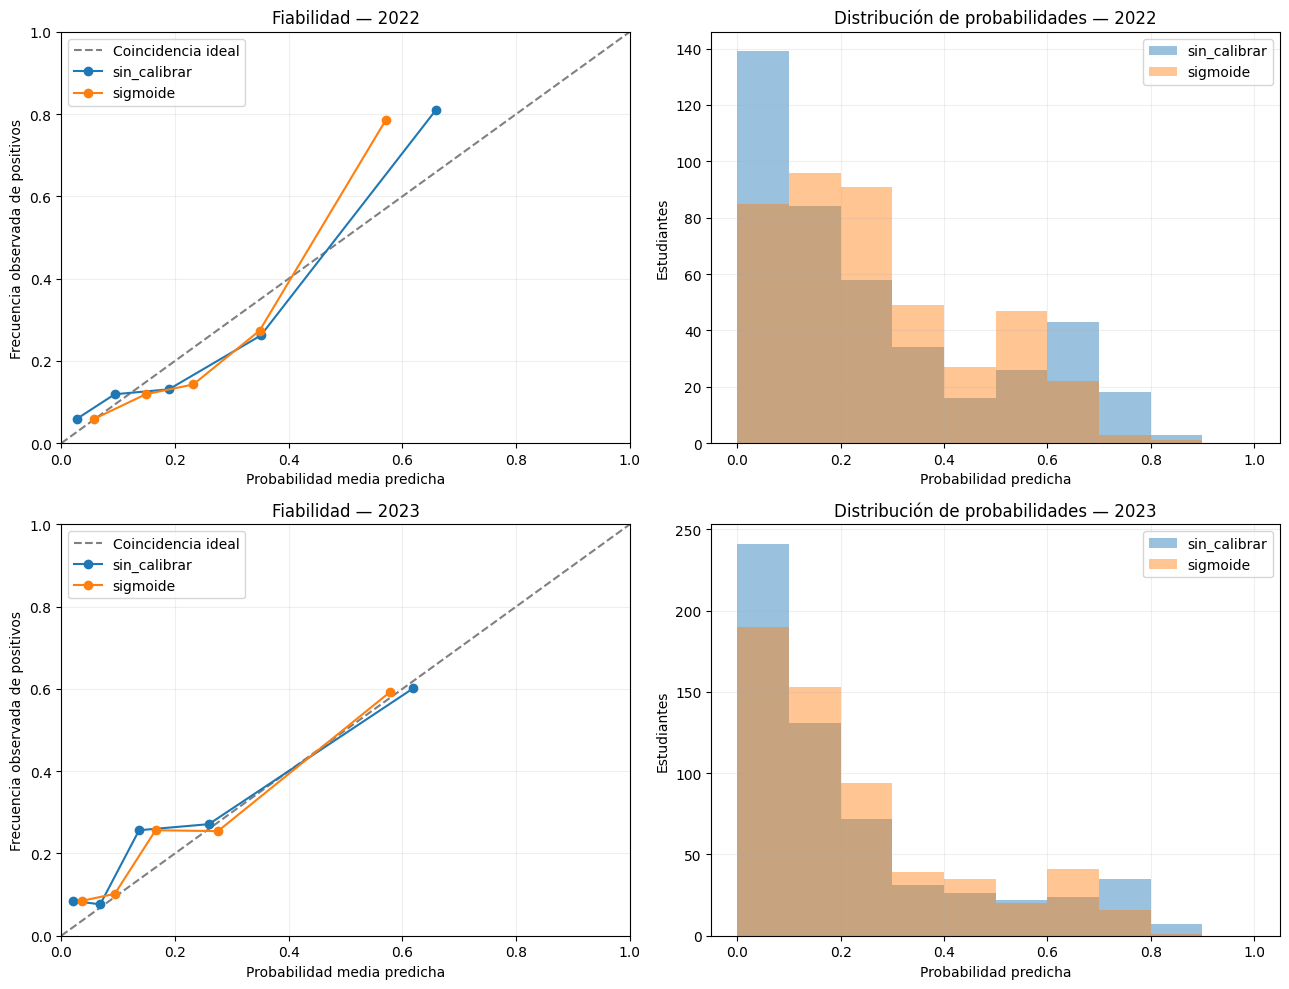

In [11]:
fig, axes = plt.subplots(
    len(ANIOS_EVALUACION), 2,
    figsize=(13, 5 * len(ANIOS_EVALUACION)),
    squeeze=False,
)

for fila, anio in enumerate(ANIOS_EVALUACION):
    ax_curva, ax_hist = axes[fila]

    ax_curva.plot(
        [0, 1], [0, 1],
        "--", color="gray", label="Coincidencia ideal",
    )

    for variante in ["sin_calibrar", "sigmoide"]:
        puntos = grupos_calibracion.loc[
            grupos_calibracion["anio_evaluacion"].eq(anio)
            & grupos_calibracion["variante"].eq(variante)
        ].sort_values("grupo")

        ax_curva.plot(
            puntos["probabilidad_media"],
            puntos["frecuencia_observada"],
            marker="o",
            label=variante,
        )

        prob = predicciones_calibracion.loc[
            predicciones_calibracion["anio_academico"].eq(anio)
            & predicciones_calibracion["variante"].eq(variante),
            "probabilidad_abandono",
        ]

        ax_hist.hist(
            prob,
            bins=np.linspace(0, 1, 11),
            alpha=0.45,
            label=variante,
        )

    ax_curva.set_title(f"Fiabilidad — {anio}")
    ax_curva.set_xlabel("Probabilidad media predicha")
    ax_curva.set_ylabel("Frecuencia observada de positivos")
    ax_curva.set_xlim(0, 1)
    ax_curva.set_ylim(0, 1)

    ax_hist.set_title(f"Distribución de probabilidades — {anio}")
    ax_hist.set_xlabel("Probabilidad predicha")
    ax_hist.set_ylabel("Estudiantes")

    for ax in [ax_curva, ax_hist]:
        ax.grid(alpha=0.2)
        ax.legend()

plt.tight_layout()
plt.show()


## 12. Efecto sobre cortes y capacidad ilustrativa

Después de calibrar, el mismo corte puede generar otra cantidad de alertas. Se revisan cortes predefinidos y 150 contactos, sin elegir automáticamente un umbral. Calibrar busca fiabilidad de las probabilidades, no forzar un recall alto.


In [12]:
filas_umbrales = []
filas_capacidad = []

for (anio, variante), grupo in predicciones_calibracion.groupby(
    ["anio_academico", "variante"]
):
    for umbral in CORTES_REVISION:
        alertas = grupo["probabilidad_abandono"].ge(umbral)
        filas_umbrales.append({
            "anio_evaluacion": int(anio),
            "variante": variante,
            "umbral": umbral,
            **resumir_alertas(grupo, alertas),
        })

    ranking = grupo.sort_values(
        ["probabilidad_abandono", "id_alumno"],
        ascending=[False, True],
    )
    cantidad = min(CAPACIDAD_EJEMPLO, len(ranking))
    alertas = np.arange(len(ranking)) < cantidad

    filas_capacidad.append({
        "anio_evaluacion": int(anio),
        "variante": variante,
        "capacidad": CAPACIDAD_EJEMPLO,
        **resumir_alertas(ranking, alertas),
    })

metricas_umbrales = pd.DataFrame(filas_umbrales)
metricas_capacidad = pd.DataFrame(filas_capacidad)

print("Cortes predefinidos:")
display(metricas_umbrales.round(4))

print(f"Capacidad ilustrativa: {CAPACIDAD_EJEMPLO} contactos")
display(metricas_capacidad.round(4))


Cortes predefinidos:


,anio_evaluacion,variante,umbral,registros,positivos,alertas,verdaderos_positivos,falsos_positivos,falsos_negativos,precision,recall
0,2022,sigmoide,0.5,421,116,73,61,12,55,0.8356,0.5259
1,2022,sigmoide,0.4,421,116,100,74,26,42,0.7400,0.6379
2,2022,sigmoide,0.3,421,116,149,86,63,30,0.5772,0.7414
3,2022,sigmoide,0.2,421,116,240,99,141,17,0.4125,0.8534
4,2022,sin_calibrar,0.5,421,116,90,71,19,45,0.7889,0.6121
5,2022,sin_calibrar,0.4,421,116,106,76,30,40,0.7170,0.6552
6,2022,sin_calibrar,0.3,421,116,140,82,58,34,0.5857,0.7069
7,2022,sin_calibrar,0.2,421,116,198,94,104,22,0.4747,0.8103
8,2023,sigmoide,0.5,589,152,78,59,19,93,0.7564,0.3882
9,2023,sigmoide,0.4,589,152,113,69,44,83,0.6106,0.4539


Capacidad ilustrativa: 150 contactos


,anio_evaluacion,variante,capacidad,registros,positivos,alertas,verdaderos_positivos,falsos_positivos,falsos_negativos,precision,recall
0,2022,sigmoide,150,421,116,150,87,63,29,0.58,0.7500
1,2022,sin_calibrar,150,421,116,150,87,63,29,0.58,0.7500
2,2023,sigmoide,150,589,152,150,81,69,71,0.54,0.5329
3,2023,sin_calibrar,150,589,152,150,81,69,71,0.54,0.5329


## 13. Guardado del análisis

Se generan siete CSV de calibración. El paquete final se definirá después de revisar si calibrar aporta una ventaja; este cuaderno no sobrescribe configuraciones, datos ni modelos anteriores.


In [13]:
CARPETA_REPORTES.mkdir(parents=True, exist_ok=True)

reportes = {
    "calibracion_metricas_folds.csv": metricas_folds,
    "calibracion_metricas_anuales.csv": metricas_anuales,
    "calibracion_diferencias_folds.csv": diferencias_folds,
    "calibracion_predicciones.csv": predicciones_calibracion,
    "calibracion_grupos.csv": grupos_calibracion,
    "calibracion_umbrales.csv": metricas_umbrales,
    "calibracion_capacidad.csv": metricas_capacidad,
}

for nombre, datos in reportes.items():
    datos.to_csv(CARPETA_REPORTES / nombre, index=False)
    print("Guardado:", nombre)


Guardado: calibracion_metricas_folds.csv
Guardado: calibracion_metricas_anuales.csv
Guardado: calibracion_diferencias_folds.csv
Guardado: calibracion_predicciones.csv
Guardado: calibracion_grupos.csv
Guardado: calibracion_umbrales.csv
Guardado: calibracion_capacidad.csv


## Conclusiones de la calibración

Se evaluó la logística con recuentos con cinco folds externos por estudiante y tres internos para calibrar. El calibrador no utilizó los estudiantes ni las etiquetas de evaluación externa. La tabla agrupa las predicciones de cada año; precisión y recall usan corte 0,50.

| Año | Variante | Brier | Log loss | Precisión | Recall |
|---|---|---:|---:|---:|---:|
| 2022 | Sin calibrar | **0,1295** | **0,4184** | 78,89 % | 61,21 % |
| 2022 | Sigmoide | 0,1379 | 0,4364 | 83,56 % | 52,59 % |
| 2023 | Sin calibrar | 0,1487 | 0,4750 | 70,45 % | 40,79 % |
| 2023 | Sigmoide | **0,1482** | **0,4661** | 75,64 % | 38,82 % |

- **La mejora probabilística no fue consistente.** En 2022 la sigmoide empeoró Brier en los cinco folds. En 2023 lo mejoró ligeramente en tres de cinco folds.
- **La discriminación por fold se mantuvo.** ROC-AUC y Average Precision no cambiaron dentro de cada fold; las pequeñas diferencias agrupadas provienen de combinar mapas de calibración distintos entre folds.
- **El mismo corte produjo menos alertas.** La precisión aumentó y el recall disminuyó en ambos años. Con 150 contactos, las dos variantes detectaron la misma cantidad de positivos: 87 en 2022 y 81 en 2023.

**Decisión provisional:** conservar la logística con recuentos sin recalibración adicional como candidata para el cierre. Se evaluó la sigmoide, pero no se adopta por defecto porque no aportó una ventaja consistente entre años. Esto no demuestra calibración perfecta de la variante original.

Quedan por completar explicabilidad, intervalos de confianza, definición operativa y empaquetado reproducible. Los 150 contactos y el corte 0,50 siguen siendo referencias; los años ya inspeccionados no constituyen un test independiente. Si cambian los resultados, deben actualizarse estas conclusiones.
